# CommerceIQ — Phase 12 (Model B): Purchase-Time Delivery Delay Risk Classification

**Prediction Moment:** Order checkout (`order_purchase_timestamp`).  
**Leakage Prevention:** Strictly excludes actual delivery dates, carrier handover dates, actual durations, review scores, and future seller outcomes. Seller historical late rates are computed in event-time using only orders already delivered prior to the current purchase timestamp.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.forecasting.delivery_risk_model import run_delivery_risk_pipeline

res = run_delivery_risk_pipeline()
print("Temporal Splits:", res["splits"])
print("Selected Best Model (by Test PR-AUC):", res["best_model"])

Temporal Splits: {'train': 57317, 'val': 20550, 'test': 18603}
Selected Best Model (by Test PR-AUC): Hist_Gradient_Boosting


## 1. Model Comparison on Unseen Temporal Test Split (>= 2018-06-01)

In [2]:
display(res["comparison"])
print("Confusion Matrix [TN, FP; FN, TP]:", res["confusion_matrix"])

Confusion Matrix [TN, FP; FN, TP]: [[13666, 4265], [274, 398]]


,model,val_roc_auc,val_pr_auc,test_roc_auc,test_pr_auc,val_opt_threshold,test_precision,test_recall,test_f1,test_brier
0,Hist_Gradient_Boosting,0.6980,0.1966,0.7325,0.0771,0.4709,0.0854,0.5923,0.1492,0.1629
1,Logistic_Regression,0.7230,0.2241,0.6581,0.0629,0.6344,0.0661,0.2411,0.1038,0.2154
2,Decision_Tree,0.6595,0.1617,0.6169,0.0559,0.4751,0.0633,0.3839,0.1087,0.1707
3,Random_Forest,0.7035,0.2082,0.6354,0.0519,0.4923,0.0520,0.1399,0.0758,0.1595
4,Dummy_Stratified,0.4967,0.1005,0.5039,0.0364,0.0000,0.0361,1.0000,0.0697,0.0963


## 2. Purchase-Time Drivers (Permutation Importance) & Diagnostic Plot

Saved model to models/delivery_risk_model.joblib, test predictions to data/processed/delivery_risk_predictions.csv, and model card to reports/delivery_risk_model_card.md


,feature,importance_mean,importance_std
0,estimated_delivery_days,0.04688,0.00033
1,approx_distance_km,0.01390,0.00276
2,is_same_state,0.00614,0.00524
3,category_grouped,0.00287,0.00043
4,primary_payment_type,0.00170,0.00072
5,distinct_sellers,0.00136,0.00117
6,customer_region,0.00107,0.00447
7,item_count,0.00096,0.00060
8,purchase_hour,0.00083,0.00122
9,seller_prior_late_rate,0.00058,0.00196


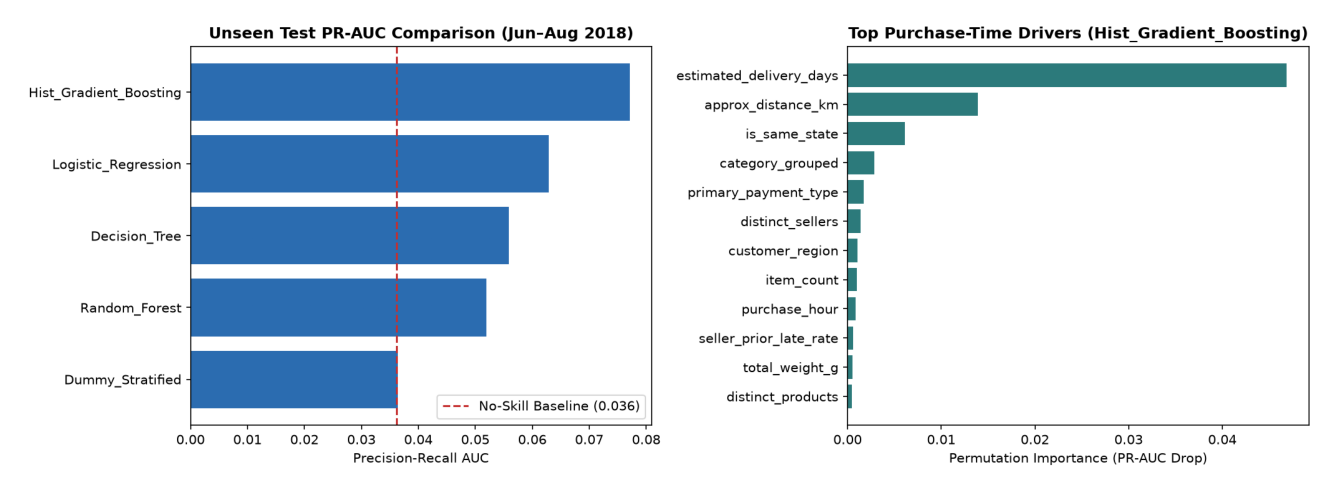

In [3]:
display(res["importance"].head(15).round(5))

img = mpimg.imread(PROJECT_ROOT / "reports" / "figures" / "pred_02_delivery_risk_performance.png")
fig, ax = plt.subplots(figsize=(13, 5))
ax.imshow(img)
ax.axis("off")
plt.show()
print("Saved model to models/delivery_risk_model.joblib, test predictions to data/processed/delivery_risk_predictions.csv, and model card to reports/delivery_risk_model_card.md")